# StarMatch – examples

**Part A – astrometry:** match a daophot star list to a sky catalogue (Gaia) and get the
transformation pixels ↔ RA/Dec (and a FITS WCS header).

**Part B – two pixel lists:** the transformation between two instrumental catalogues
(2nd-order polynomial).

```console
pip install -e ".[notebook]"
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import starmatch
from starmatch import load_catalog, load_sky_catalog, load_xytr, match, match_sky

DATA = Path("../data")
print("starmatch", starmatch.__version__)
sorted(p.name for p in DATA.iterdir())

starmatch 0.3.0


['CEP02_081212_1_J.ap',
 'CEP02_081215_1_J.ap',
 'CEP02_151230_K_CHIP3.out',
 'FS001_121011_1_J.ap',
 'FS001_gaia.txt',
 'FS114_121010_1_J.ap',
 'SMC24_131127_1_K.out',
 'SMC24_181228_1_K.out']

# Part A – astrometry with Gaia

## A1. Quick start

SOFI image of the standard field FS001 (`FS001_121011_1_J.ap`, J band, 0.288"/px) and Gaia DR3 stars
around it (`FS001_gaia.txt`: `ra dec G pmra pmdec`). The `epoch` of the observation (FITS `DATE-OBS`)
moves the Gaia positions (epoch 2016.0) with proper motions.

In [2]:
r = match_sky(DATA / "FS001_121011_1_J.ap", DATA / "FS001_gaia.txt", pixscale=0.288, epoch="2012-10-12T01:46:40")
r

SkyMatchResult(n=19 stars, rms=0.066", pixscale=0.2880"/px, PA=269.97 deg, order=1)

`r.transform` converts in both directions; `r.radec()` gives RA/Dec of all stars in the list:

In [3]:
t = r.transform
print(t)
print("pixel (500, 500) ->", t.pix_to_sky(500.0, 500.0))
ra, dec = r.radec()
print("first 3 stars (x, y, ra, dec):")
print(np.c_[r.field.x[:3], r.field.y[:3], ra[:3], dec[:3]])

SkyTransform(pixscale=0.2880"/px, PA=269.973 deg)
pixel (500, 500) -> (np.float64(8.48161607339744), np.float64(-12.130210498187987))
first 3 stars (x, y, ra, dec):
[[695.38       803.64         8.45676332 -12.14584789]
 [543.2        550.37         8.47749336 -12.13366763]
 [969.1        730.41         8.46275137 -12.16773866]]


## A2. Matched stars and residuals

`r.field_idx` / `r.cat_idx` are indices of the matched pairs, `r.residuals` the (catalogue − fit)
offsets in arcsec. With fewer than 30 pairs a linear transformation is fitted (`order=1`).

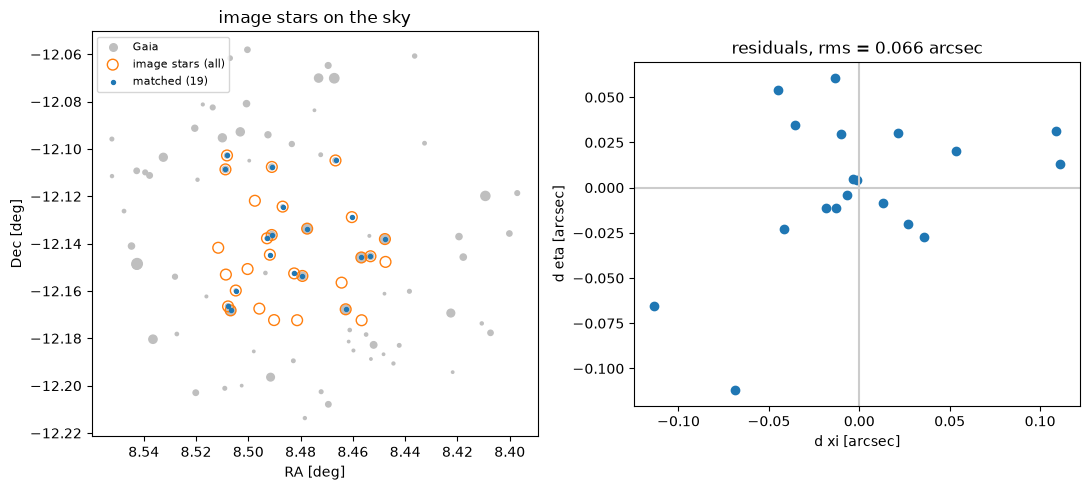

In [4]:
res = r.residuals
cat = r.catalog
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].scatter(cat.ra, cat.dec, s=np.clip(21.5 - cat.mag, 0.5, None) * 6, c="0.75", label="Gaia")
ax[0].scatter(ra, dec, s=60, facecolors="none", edgecolors="tab:orange", label="image stars (all)")
ax[0].scatter(cat.ra[r.cat_idx], cat.dec[r.cat_idx], s=8, c="tab:blue", label=f"matched ({r.n})")
ax[0].invert_xaxis(); ax[0].set_xlabel("RA [deg]"); ax[0].set_ylabel("Dec [deg]"); ax[0].legend(fontsize=8)
ax[0].set_title("image stars on the sky")
ax[1].scatter(*res.T)
ax[1].set_aspect("equal"); ax[1].axhline(0, c="0.8"); ax[1].axvline(0, c="0.8")
ax[1].set_xlabel("d xi [arcsec]"); ax[1].set_ylabel("d eta [arcsec]")
ax[1].set_title(f"residuals, rms = {r.rms:.3f} arcsec")
plt.tight_layout()

## A3. Proper motions matter

The same match without the epoch correction (Gaia positions at 2016.0, image from 2012.8):

In [5]:
r_nopm = match_sky(DATA / "FS001_121011_1_J.ap", DATA / "FS001_gaia.txt", pixscale=0.288)
print("with proper motions:   ", r)
print("without proper motions:", r_nopm)

with proper motions:    SkyMatchResult(n=19 stars, rms=0.066", pixscale=0.2880"/px, PA=269.97 deg, order=1)
without proper motions: SkyMatchResult(n=18 stars, rms=0.079", pixscale=0.2880"/px, PA=269.97 deg, order=1)


## A4. FITS WCS, saving

`wcs_header()` gives FITS keywords (`RA---TAN`, or `RA---TAN-SIP` for a 2nd-order solution);
with astropy: `r.transform.wcs()`. The image of this field is rotated by 90° (PA = 270°) –
the default `CD` matrix in the original FITS header (no rotation) is wrong.

In [6]:
for k, v in r.wcs_header().items():
    print(f"{k:8s} = {v}")
r.save("FS001.radec")                 # text file, like .xytr
r.save_wcs("FS001.wcs")               # FITS header cards
r.save_pairs("FS001.pairs")           # matched stars with residuals
print(open("FS001.pairs").read().splitlines()[:3])
for f in ("FS001.radec", "FS001.wcs", "FS001.pairs"):
    Path(f).unlink()

WCSAXES  = 2
CTYPE1   = RA---TAN
CTYPE2   = DEC--TAN
CUNIT1   = deg
CUNIT2   = deg
RADESYS  = ICRS
CRPIX1   = 611.2953065626529
CRPIX2   = 488.40388033482304
CRVAL1   = 8.482563617914652
CRVAL2   = -12.139111831860147
CD1_1    = -1.262195516658472e-08
CD1_2    = -8.000892455477765e-05
CD2_1    = -7.998332942916802e-05
CD2_2    = -3.768800498466535e-08
['# id_field x y mag id_cat ra dec mag_cat dxi[arcsec] deta[arcsec]', '1 695.380 803.640 13.6280 9 8.45676295 -12.14584678 14.6676 -0.0013 0.0040', '2 543.200 550.370 14.1530 0 8.47750103 -12.13367318 14.6800 0.0270 -0.0200']


## A5. Getting the Gaia catalogue and the epoch

```python
from starmatch import read_fits_header
from starmatch.gaia import query_gaia            # VizieR, no extra packages needed

h = read_fits_header("FS001_121011_1_J.fits")
gaia = query_gaia(h["RA"], h["DEC"], radius_arcmin=5)
r = match_sky("FS001_121011_1_J.ap", gaia, pixscale=h["ESO INS PIXSCALE"], epoch=h["DATE-OBS"])
```

or from the terminal:

```console
starmatch gaia --fits FS001_121011_1_J.fits --radius 5 -o FS001_gaia.txt
starmatch sky FS001_121011_1_J.ap FS001_gaia.txt --pixscale 0.288 --fits FS001_121011_1_J.fits --wcs FS001.wcs
```

In [7]:
!starmatch sky ../data/FS001_121011_1_J.ap ../data/FS001_gaia.txt --pixscale 0.288 --epoch 2012.78 -o fs.radec
!cat fs.radec && rm fs.radec

SkyMatchResult(n=19 stars, rms=0.066", pixscale=0.2880"/px, PA=269.97 deg, order=1)
tangent point: RA=8.482564 Dec=-12.139112
residuals rms: 0.066 arcsec (19 stars)
saved: fs.radec


# field=../data/FS001_121011_1_J.ap catalog=../data/FS001_gaia.txt
# (xi, eta) [arcsec] = gnomonic (TAN) standard coordinates around (RA0, DEC0) [deg]
# xi  = pxi[0]  + pxi[1] * x + pxi[2] * y + pxi[3] * x*y + pxi[4] * x*x + pxi[5] * y*y
# x   = px[0]   + px[1] * xi + px[2] * eta + px[3] * xi*eta + px[4] * xi*xi + px[5] * eta*eta
TAN RA0= 8.482563619157101 DEC0= -12.139111834624922
# Pixel to sky
P2S Pxi=  140.7037820747534 -4.5436305512305216e-05 -0.2880321188618708 0.0 0.0 0.0 
P2S Peta=  176.08260895536316 -0.2879399594237 -0.00013569862460711794 0.0 0.0 0.0 
# Sky to pixel
S2P Px=  611.2952592119058 0.0016367777591430777 -3.472945530168789 0.0 0.0 0.0 
S2P Py=  488.40388488761533 -3.471833278382089 0.0005483185869592514 0.0 0.0 0.0 


# Part B – two pixel lists

## B1. Quick start

Give two files (or arrays) and the pixel scale ratio `pixscale` = field/reference (default 1).
The algorithm is deterministic and usually takes a few tens of milliseconds.

In [8]:
r = match(DATA / "SMC24_131127_1_K.out", DATA / "SMC24_181228_1_K.out")
r

MatchResult(n=1422 pairs, rms=0.269 px, scale=0.99970, rotation=0.011 deg)

## B2. The result

`match` returns a `MatchResult`:

| attribute | meaning |
|---|---|
| `transform` | `XYTransform`: `field_to_ref(x, y)`, `ref_to_field(x, y)`, coefficients `fr_x, fr_y, rf_x, rf_y`, `scale`, `rotation` |
| `n`, `rms` | number of matched pairs, residual rms [reference px] |
| `ref_idx`, `field_idx` | indices of matched stars in the input catalogues |
| `ref_id`, `field_id` | daophot IDs of matched stars |
| `ref_xy`, `field_xy`, `residuals` | (n, 2) arrays |
| `save(path)`, `save_pairs(path)` | write `.xytr` / list of matched stars |

In [9]:
t = r.transform
print(t)
np.set_printoptions(precision=6, suppress=True)
print("field -> reference  px:", t.fr_x)
print("field -> reference  py:", t.fr_y)
print("\nfield star (500, 500) in the reference frame:", t.field_to_ref(500.0, 500.0))
print("first matched pairs (ID ref -> ID field):", list(zip(r.ref_id[:5].tolist(), r.field_id[:5].tolist())))

XYTransform(scale=0.99970, rotation=0.011 deg)
field -> reference  px: [-104.493409    0.999198   -0.00044     0.          0.         -0.      ]
field -> reference  py: [63.648043 -0.000053  1.000198 -0.        0.       -0.      ]

field star (500, 500) in the reference frame: (395.0267793361926, 563.740576350787)
first matched pairs (ID ref -> ID field): [(4, 1), (3, 2), (5, 3), (8, 4), (7, 5)]


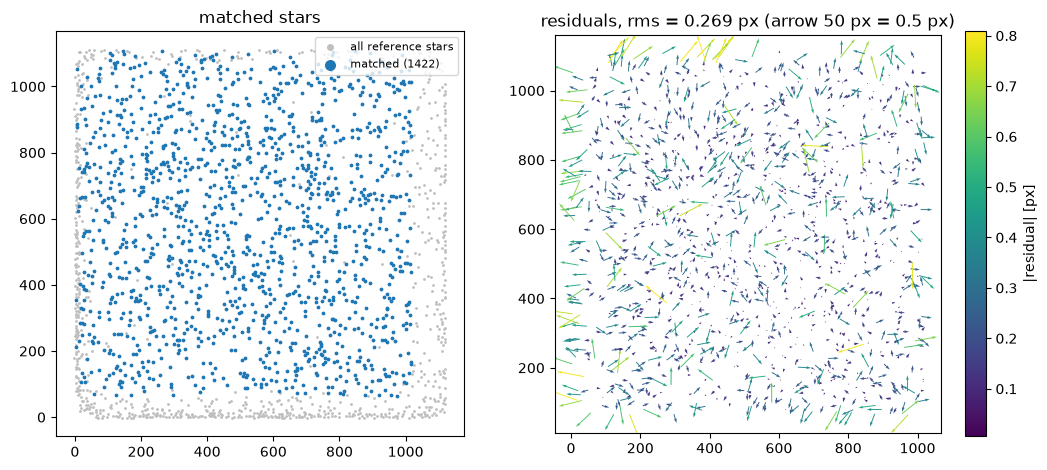

In [10]:
res = r.residuals
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].scatter(r.ref.x, r.ref.y, s=1, c="0.75", label="all reference stars")
axes[0].scatter(*r.ref_xy.T, s=3, c="tab:blue", label=f"matched ({r.n})")
axes[0].set_aspect("equal"); axes[0].legend(markerscale=4, fontsize=8, loc="upper right")
axes[0].set_title("matched stars")
q = axes[1].quiver(*r.ref_xy.T, *res.T, np.hypot(*res.T), angles="xy", scale_units="xy", scale=0.01, cmap="viridis")
axes[1].set_aspect("equal")
axes[1].set_title(f"residuals, rms = {r.rms:.3f} px (arrow 50 px = 0.5 px)")
plt.colorbar(q, ax=axes[1], label="|residual| [px]")
plt.tight_layout()

In [11]:
path = r.save("SMC24_181228_1_K.xytr")
print(path.read_text())
t2 = load_xytr(path)                      # back from file
print(t2.field_to_ref(500.0, 500.0))
r.save_pairs("SMC24_181228_1_K.pairs")
print(open("SMC24_181228_1_K.pairs").read().splitlines()[:4])
path.unlink(); Path("SMC24_181228_1_K.pairs").unlink()

# reference=../data/SMC24_131127_1_K.out field=../data/SMC24_181228_1_K.out
# x' = px[0] + px[1] * x + px[2] * y + px[3] * x*y + px[4] * x*x + px[5] * y*y
# y' = py[0] + py[1] * x + py[2] * y + py[3] * x*y + py[4] * x*x + py[5] * y*y
# Field to Reference
F2R Px=  -104.49340896448945 0.9991978660832066 -0.0004398026302071598 4.2759005614493874e-07 1.9052425855990953e-07 -5.348801797551967e-08 
F2R Py=  63.64804256713881 -5.345848796779794e-05 1.0001977755112137 -6.85486720747806e-08 3.9779448404850246e-07 -2.4774472387262975e-07 
# Reference to Field
R2F Px=  104.55087016743376 1.0007875311724017 0.0003885873538741345 -4.278688661909223e-07 -1.8892668435740576e-07 5.321254992557083e-08 
R2F Py=  -63.63360346831744 -3.422986432317878e-05 0.9997783698971913 6.829784444133422e-08 -3.981091447443378e-07 2.46982964352253e-07 

(395.0267793361926, 563.740576350787)
['# id_ref x_ref y_ref mag_ref id_field x_field y_field mag_field', '4 282.489 457.701 11.6375 1 387.498 394.026 11.5495', '3 208

## B3. Different instruments: HAWKI vs SOFI

Reference: SOFI (`CEP02_081215_1_J.ap`), field: one HAWKI chip (`CEP02_151230_K_CHIP3.out`),
pixel scale ratio HAWKI/SOFI = 0.368. `pixscale` must be known to about ±3%.

MatchResult(n=443 pairs, rms=0.255 px, scale=0.37045, rotation=90.085 deg)


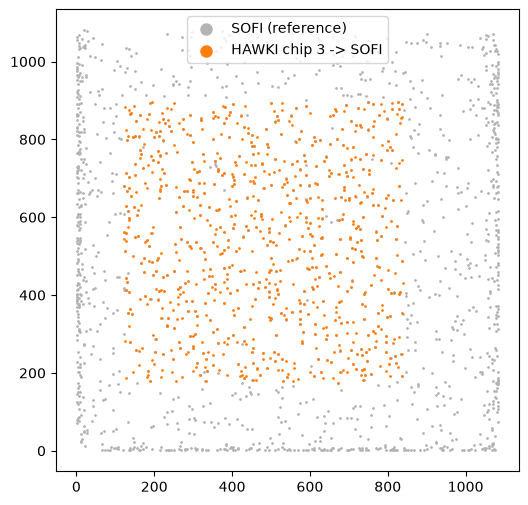

In [12]:
h = match(DATA / "CEP02_081215_1_J.ap", DATA / "CEP02_151230_K_CHIP3.out", pixscale=0.368)
print(h)

hx, hy = h.transform.field_to_ref(h.field.x, h.field.y)
plt.figure(figsize=(6, 6))
plt.scatter(h.ref.x, h.ref.y, s=1, c="0.7", label="SOFI (reference)")
plt.scatter(hx, hy, s=1, c="tab:orange", label="HAWKI chip 3 -> SOFI")
plt.gca().set_aspect("equal"); plt.legend(markerscale=8);

## B4. Input formats

`ref` and `field` can be:

* a file path – daophot `.ap` (two lines per star), `.out`, `.coo`, `.lst`, `.als`, … or a text file `ID X Y MAG`,
* a `Catalog` from `load_catalog(path, columns=(ix, iy, imag), id_column=0)`,
* a tuple `(x, y, mag)` or an (N, 3) array,
* a table / dict / DataFrame with columns `x`, `y`, `mag` (or `m`), optionally `id`.

In [13]:
cat = load_catalog(DATA / "SMC24_131127_1_K.out")
print(cat, "-> unpacks as x, y, mag; IDs:", cat.id[:5])

x, y, m = load_catalog(DATA / "SMC24_181228_1_K.out")
table = {"x": x, "y": y, "mag": m}

print(match(cat, (x, y, m)))
print(match(np.column_stack(cat), table))

Catalog(2264 stars, path='../data/SMC24_131127_1_K.out') -> unpacks as x, y, mag; IDs: [1 2 3 4 5]


MatchResult(n=1422 pairs, rms=0.269 px, scale=0.99970, rotation=0.011 deg)
MatchResult(n=1422 pairs, rms=0.269 px, scale=0.99970, rotation=0.011 deg)


## B5. How it works

1. **Local features** of the brightest stars (`nb_use`=400) – projections of neighbours on an
   axis pointing to the brightest neighbour – give a *candidate* field star for each reference star.
2. **Consensus** – every pair of candidates defines shift + rotation + scale; models with scale
   inconsistent with `pixscale` are dropped and the model agreeing with most candidates wins.
3. **Refinement** – all stars are matched with their nearest neighbour, the 2nd-order polynomial is
   fitted with 3σ clipping, iterated; the solution is accepted only if the number of matched pairs
   is far above chance coincidences.

The candidates are stored in `r.candidates` (reference, field as complex `x + iy`, consensus mask):

candidates: 49, consistent with consensus: 36, final pairs: 443


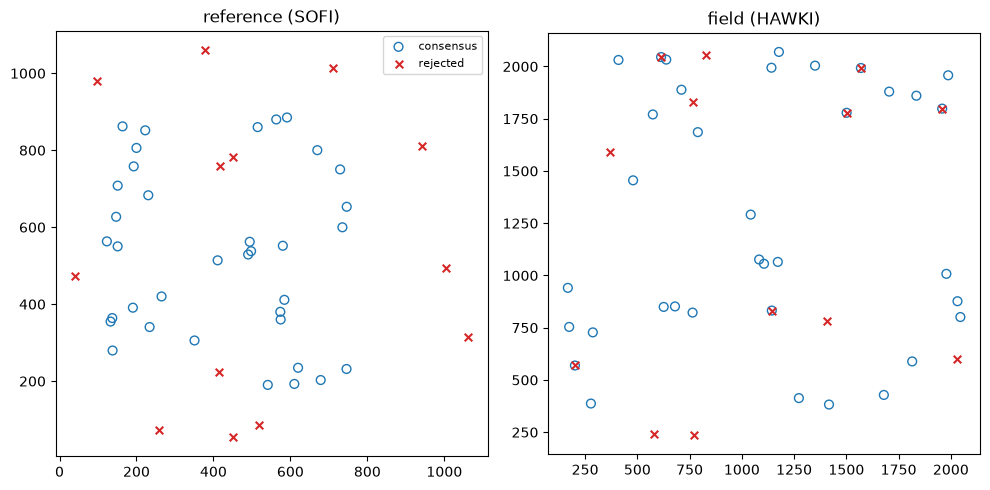

In [14]:
ref_c, fld_c, inl = h.candidates
print(f"candidates: {h.n_candidates}, consistent with consensus: {h.n_consensus}, final pairs: {h.n}")
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, c, title in [(axes[0], ref_c, "reference (SOFI)"), (axes[1], fld_c, "field (HAWKI)")]:
    ax.scatter(c.real[inl], c.imag[inl], s=40, facecolors="none", edgecolors="tab:blue", label="consensus")
    ax.scatter(c.real[~inl], c.imag[~inl], s=30, marker="x", c="tab:red", label="rejected")
    ax.set_aspect("equal"); ax.set_title(title)
axes[0].legend(fontsize=8)
plt.tight_layout()

## B6. When it fails

If no significant solution is found, `MatchError` is raised – the most common reason is a wrong
`pixscale`:

In [15]:
try:
    match(DATA / "CEP02_081215_1_J.ap", DATA / "CEP02_151230_K_CHIP3.out")   # pixscale missing
except starmatch.MatchError as e:
    print("MatchError:", e)

MatchError: no significant match (candidates=31, consensus=2, nb_use=1600) - check pixscale and flip


## B7. Synthetic test

Random star field; the field rotated by 25°, pixel scale ratio 0.5, shifted, with 0.15 px position
noise, 30% of stars missing and 100 spurious ones. The recovered transformation is compared with the truth.

In [16]:
rng = np.random.default_rng(42)
n = 3000
x = rng.uniform(0, 1000, n); y = rng.uniform(0, 1000, n)
m = 12 + np.log10(1 + rng.uniform(0, 1, n) * (10**2.7 - 1)) / 0.3

a, s, shift = np.radians(25), 2.0, (120.0, -80.0)
def truth(x, y):                       # reference -> field
    return s * (np.cos(a) * x - np.sin(a) * y) + shift[0], s * (np.sin(a) * x + np.cos(a) * y) + shift[1]

fx, fy = truth(x, y)
fx += rng.normal(0, 0.15, n); fy += rng.normal(0, 0.15, n)
keep = rng.random(n) > 0.3
fx, fy, fm = fx[keep], fy[keep], (m + 0.5)[keep]
fx = np.r_[fx, rng.uniform(fx.min(), fx.max(), 100)]
fy = np.r_[fy, rng.uniform(fy.min(), fy.max(), 100)]
fm = np.r_[fm, rng.uniform(12, 21, 100)]

syn = match((x, y, m), (fx, fy, fm), pixscale=1 / s)
print(syn)
tx, ty = truth(x, y)
px, py = syn.transform.ref_to_field(x, y)
print(f"max error of the transformation over the field: {np.hypot(px - tx, py - ty).max():.4f} px")

MatchResult(n=2090 pairs, rms=0.106 px, scale=0.50000, rotation=-25.001 deg)
max error of the transformation over the field: 0.0356 px


## B8. Legacy `StarMatch` class

The attribute-style interface of the original scripts still works (it calls `match` internally):

In [17]:
from starmatch import StarMatch

sm = StarMatch(pixscale=0.368, loud=True)
sm.ref_xr, sm.ref_yr, sm.ref_mr = load_catalog(DATA / "CEP02_081215_1_J.ap")
sm.field_xr, sm.field_yr, sm.field_mr = load_catalog(DATA / "CEP02_151230_K_CHIP3.out")
sm.go()
print(sm.mssg)
print(sm.p_fr_x)


stars used: 400
candidates from local features: 49
candidates consistent with consensus: 36
matched pairs: 443, rms = 0.255 px
[889.219387  -0.001136  -0.36972   -0.         0.         0.      ]


## B9. Command line

In [18]:
!starmatch pix ../data/CEP02_081215_1_J.ap ../data/CEP02_151230_K_CHIP3.out --pixscale 0.368 -o hawki.xytr --pairs hawki.pairs
!head -3 hawki.pairs && rm hawki.xytr hawki.pairs

MatchResult(n=443 pairs, rms=0.255 px, scale=0.37045, rotation=90.085 deg)
X field to reference: [ 8.892194e+02 -1.135880e-03 -3.697198e-01 -7.461100e-10  1.151281e-07
  5.546055e-08]
Y field to reference: [ 1.285173e+02  3.711856e-01  3.034348e-05 -4.515845e-07 -4.296079e-07
 -1.609812e-07]
X reference to field: [-3.447915e+02 -4.302726e-03  2.699807e+00 -8.958365e-06  3.210021e-06
  8.469525e-06]
Y reference to field: [ 2.407084e+03 -2.706691e+00 -8.896859e-03  2.993427e-08  1.092224e-06
  2.258704e-06]
pairs saved: hawki.pairs
saved: hawki.xytr


# id_ref x_ref y_ref mag_ref id_field x_field y_field mag_field
1279 563.190 880.049 13.2650 1 2031.761 876.822 9.3870
838 580.276 551.822 13.3540 2 1143.220 832.246 9.7110
